# Final revision — Step 7

Run this notebook from this copied project folder, or set `NETWORK_ANALYSIS_LOCAL_ROOT` to its absolute path. Run Steps 01–07 in separate kernels. Existing outputs in this copy may be overwritten; the source repository is untouched.

The approved hypotheses, thresholds, seeds, null ensembles and removal protocol are retained. Cleared outputs avoid presenting historical execution as validation of revised code. Step 04 is the full historical generation workflow and is computationally expensive; the supplied cached ensembles allow Steps 05–07 to run without regenerating it. Consult `VALIDATION.md` for exactly what was rerun.


# Step 7: Single-airport removal and H3 evaluation

**Scope.** This notebook removes each observed airport individually, calculates the approved loss measures, and applies the approved H3 evaluation. Randomized networks are not used.

**Primary outcome.** ΔE_i = Efficiency(G, none removed) − Efficiency(G, {i} removed), with the original N(N−1) denominator.

**Supplementary outcome.** For the surviving airports S (all airports except i), D_i is the mean of 1/d across ordered pairs in S before removal minus the same mean after removal, each with denominator (N−1)(N−2).

**Identity used as a calculation check.** ΔE_i = direct_i / (N(N−1)) + ((N−2)/N) × D_i, where direct_i sums 1/d over all ordered pairs involving i.

**Interpretation.** These results show association or predictive improvement in observed structure. They are not causal claims. The 0.02 R² threshold is a project-specific practical-effect threshold, not a universal statistical standard.

## Section 7.0: Setup and accepted inputs

In [1]:
import hashlib
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import scipy
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import shortest_path

# Local execution is enabled only when this environment variable is set.
# It is not set on Colab, so Colab always uses the Google Drive path below.
LOCAL_PROJECT_ROOT = os.environ.get("NETWORK_ANALYSIS_LOCAL_ROOT")

if LOCAL_PROJECT_ROOT:
    BASE = Path(LOCAL_PROJECT_ROOT).expanduser().resolve() / "Data"
elif (Path.cwd() / "Data").is_dir():
    BASE = Path.cwd() / "Data"
else:
    from google.colab import drive
    drive.mount("/content/drive")

    # Notice the trailing space after 'Network Analysis '
    BASE = Path("/content/drive/MyDrive/Network Analysis /Data")

PROCESSED = BASE / "Processed"
H3_STORE = PROCESSED / "H3"
PROJECT_ROOT = BASE.parent
TABLES = PROJECT_ROOT / "Results" / "Tables"
FIGURES = PROJECT_ROOT / "Results" / "Figures"
H3_STORE.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

AIRLINES = ["AA", "DL", "WN"]
AIRLINE_INDEX = {a: i for i, a in enumerate(AIRLINES)}
MASTER_SEED = 20250401
STAGE_H3_BOOTSTRAP = 8
BOOTSTRAPS = 2000
GAIN_THRESHOLD = 0.02
TOP_K = [10, 20]
EXPECTED_ELIGIBLE = {"AA": 175, "DL": 142, "WN": 102}
MIN_BIN_AIRPORTS = 5
LOUVAIN_RUNS = 100

validation = []
timings = {}


class StopProtocolError(RuntimeError):
    pass


def check(name, condition, detail=""):
    if not bool(condition):
        pd.DataFrame(validation).to_csv(TABLES / "07_validation_checks.csv", index=False)
        raise StopProtocolError(f"FAILED: {name}. {detail}")
    validation.append({"Check": name, "Result": "PASS", "Detail": str(detail)})


master = pd.read_csv(TABLES / "03_airport_master.csv", dtype={"Degree bin": str})
weighted_participation = pd.read_csv(TABLES / "03_bridging_weighted_participation.csv")
run_labels = pd.read_csv(TABLES / "03_louvain_run_labels_binary.csv")
step6_intact = pd.read_csv(TABLES / "06_intact_baselines.csv")
OBS = {}

for airline in AIRLINES:
    nodes = pd.read_csv(PROCESSED / f"{airline}_nodes.csv")
    edges = pd.read_csv(PROCESSED / f"{airline}_edges.csv")
    ids = np.sort(nodes["airport_id"].to_numpy(dtype=np.int64))
    info = master[master["Airline"] == airline].sort_values("AirportID").reset_index(drop=True)
    assert np.array_equal(info["AirportID"].to_numpy(), ids)
    OBS[airline] = {
        "ids": ids, "n": len(ids), "info": info,
        "source": np.searchsorted(ids, edges["source"].to_numpy(dtype=np.int64)),
        "target": np.searchsorted(ids, edges["target"].to_numpy(dtype=np.int64))
    }

print("Accepted inputs loaded for", ", ".join(AIRLINES))

Accepted inputs loaded for AA, DL, WN


## Section 7.1: Single-airport removal

Each airport is removed once, and the remaining network is evaluated using the original airport set as its universe.

In [2]:
def inverse_distance_matrix(source, target, n, removed=None):
    A = csr_matrix((np.ones(len(source), dtype=float), (source, target)), shape=(n, n))
    if removed is not None:
        keep = np.ones(n, dtype=bool)
        keep[removed] = False
        A = A[keep, :][:, keep]
    d = shortest_path(A, method="D", unweighted=True, directed=True)
    inverse = np.zeros_like(d)
    reachable = np.isfinite(d) & (d > 0)
    inverse[reachable] = 1.0 / d[reachable]
    return inverse


single_rows = []
started = time.perf_counter()

for airline in AIRLINES:
    obs = OBS[airline]
    n, source, target = obs["n"], obs["source"], obs["target"]
    before = inverse_distance_matrix(source, target, n)
    denominator = n * (n - 1)
    survivor_denominator = (n - 1) * (n - 2)
    intact_efficiency = before.sum() / denominator
    info = obs["info"]

    for i in range(n):
        after = inverse_distance_matrix(source, target, n, removed=i)
        efficiency_after = after.sum() / denominator
        keep = np.ones(n, dtype=bool)
        keep[i] = False
        survivors_before = before[keep, :][:, keep].sum() / survivor_denominator
        survivors_after = after.sum() / survivor_denominator
        direct = before[i, :].sum() + before[:, i].sum()
        loss = intact_efficiency - efficiency_after
        damage = survivors_before - survivors_after
        row = info.iloc[i]
        single_rows.append({
            "Airline": airline, "AirportID": int(obs["ids"][i]), "Code": row["Code"], "Degree": int(row["Degree"]),
            "Eligible (degree >= 2)": bool(row["Eligible (degree >= 2)"]),
            "Betweenness": row["Betweenness"], "Core number": int(row["Core number"]),
            "Participation mean": row["Participation mean"], "Total strength (supplementary)": row["Total strength"],
            "Degree bin": row["Degree bin"], "Bin airports": row["Bin airports"], "Bin assessable": row["Bin assessable"],
            "Intact efficiency": intact_efficiency, "Efficiency after removal": efficiency_after,
            "Efficiency loss": loss, "Relative efficiency loss": loss / intact_efficiency,
            "Direct contribution": direct,
            "Survivor efficiency before": survivors_before, "Survivor efficiency after": survivors_after,
            "Surviving-airport damage": damage, "Relative surviving-airport damage": damage / survivors_before
        })

single_df = pd.DataFrame(single_rows)
single_df.to_csv(TABLES / "07_single_airport_outcomes.csv", index=False)
timings["Single-airport removal"] = time.perf_counter() - started

eligible_df = single_df[single_df["Eligible (degree >= 2)"]].copy()
display(single_df.groupby("Airline").agg(Airports=("AirportID", "count"), Eligible=("Eligible (degree >= 2)", "sum"),
                                         Maximum_loss=("Efficiency loss", "max"), Median_loss=("Efficiency loss", "median")).round(5))

,Airports,Eligible,Maximum_loss,Median_loss
Airline,,,,
AA,230,175,0.12851,0.00427
DL,212,142,0.14088,0.00446
WN,104,102,0.02376,0.01037


## Section 7.2: Validation of the single-airport results

Validation runs before any H3 evaluation. A failure stops the notebook.

In [3]:
for airline in AIRLINES:
    obs = OBS[airline]
    n = obs["n"]
    data = single_df[single_df["Airline"] == airline]
    check(f"{airline}: one row per airport", len(data) == n and data["AirportID"].is_unique, len(data))

    intact = step6_intact[(step6_intact["Airline"] == airline) & (step6_intact["Network set"] == "observed")]["Intact efficiency"].iloc[0]
    check(f"{airline}: intact efficiency matches Step 6", np.isclose(data["Intact efficiency"].iloc[0], intact, rtol=0, atol=1e-12))

    identity = data["Direct contribution"] / (n * (n - 1)) + ((n - 2) / n) * data["Surviving-airport damage"]
    check(f"{airline}: decomposition identity holds for every airport", np.allclose(data["Efficiency loss"], identity, rtol=0, atol=1e-12), n)
    check(f"{airline}: surviving-airport damage is non-negative", (data["Surviving-airport damage"] >= -1e-12).all())
    zero_b = data[data["Betweenness"] == 0]
    check(f"{airline}: zero-betweenness airports have zero surviving-airport damage", (zero_b["Surviving-airport damage"].abs() <= 1e-12).all(), len(zero_b))
    check(f"{airline}: eligible airport count", int(data["Eligible (degree >= 2)"].sum()) == EXPECTED_ELIGIBLE[airline], int(data["Eligible (degree >= 2)"].sum()))

    G = nx.DiGraph()
    G.add_nodes_from(range(n))
    G.add_edges_from(zip(obs["source"].tolist(), obs["target"].tolist()))
    check(f"{airline}: degree matches the network", all(G.out_degree(i) == G.in_degree(i) == data["Degree"].iloc[i] for i in range(n)))
    sample = np.linspace(0, n - 1, 8, dtype=int).tolist() + np.argsort(-data["Degree"].to_numpy())[:3].tolist()

    for i in sample:
        H = G.copy()
        H.remove_node(i)
        lengths = [d for u, targets in nx.all_pairs_shortest_path_length(H) for v, d in targets.items() if u != v]
        efficiency_nx = sum(1 / d for d in lengths) / (n * (n - 1))
        check(f"{airline} airport index {i}: efficiency after removal matches NetworkX", np.isclose(efficiency_nx, data["Efficiency after removal"].iloc[i], rtol=0, atol=1e-12))

check("All airports retained in descriptive output", len(single_df) == sum(OBS[a]["n"] for a in AIRLINES), len(single_df))

## Section 7.3: Associations and top-k comparisons

Spearman correlations and top-k overlaps are descriptive. "Eligible" is the degree ≥ 2 population used for H3; "All airports" retains every airport. Strength is supplementary. Rankings use descending values with ties by ascending BTS ID.

In [4]:
MEASURE_COLUMNS = {"Degree": "Degree", "Betweenness": "Betweenness", "Core number": "Core number",
                   "Mean participation": "Participation mean", "Total strength (supplementary)": "Total strength (supplementary)"}
spearman_rows, topk_rows = [], []

for airline in AIRLINES:
    for population, frame in [("Eligible (degree >= 2)", eligible_df), ("All airports", single_df)]:
        data = frame[frame["Airline"] == airline].reset_index(drop=True)
        ids = data["AirportID"].to_numpy()
        loss_order = np.lexsort((ids, -data["Efficiency loss"].to_numpy()))

        for label, column in MEASURE_COLUMNS.items():
            spearman_rows.append({"Airline": airline, "Population": population, "Measure": label, "Airports": len(data),
                                  "Spearman with efficiency loss": data[column].corr(data["Efficiency loss"], method="spearman")})
            measure_order = np.lexsort((ids, -data[column].to_numpy(dtype=float)))
            for k in TOP_K:
                overlap = len(set(loss_order[:k].tolist()) & set(measure_order[:k].tolist()))
                topk_rows.append({"Airline": airline, "Population": population, "Measure": label, "k": k,
                                  "Airports in both top k": overlap, "Overlap share": overlap / k})

spearman_df = pd.DataFrame(spearman_rows)
topk_df = pd.DataFrame(topk_rows)
spearman_df.to_csv(TABLES / "07_spearman_correlations.csv", index=False)
topk_df.to_csv(TABLES / "07_topk_overlap.csv", index=False)
display(spearman_df.pivot_table(index=["Population", "Measure"], columns="Airline", values="Spearman with efficiency loss").round(3))
display(topk_df.pivot_table(index=["Population", "Measure", "k"], columns="Airline", values="Airports in both top k"))

top_rows = []
for airline in AIRLINES:
    data = single_df[single_df["Airline"] == airline]
    for rank, (_, row) in enumerate(data.nlargest(10, "Efficiency loss").iterrows(), 1):
        top_rows.append({"Airline": airline, "Rank": rank, "Code": row["Code"], "Degree": row["Degree"], "Efficiency loss": row["Efficiency loss"],
                         "Relative efficiency loss": row["Relative efficiency loss"], "Surviving-airport damage": row["Surviving-airport damage"],
                         "Betweenness": row["Betweenness"], "Core number": row["Core number"], "Mean participation": row["Participation mean"]})
top_losses_df = pd.DataFrame(top_rows)
top_losses_df.to_csv(TABLES / "07_top_efficiency_loss_airports.csv", index=False)
display(top_losses_df.round(4))

Airline                                                   AA     DL     WN
Population             Measure                                            
All airports           Betweenness                     0.639  0.622  0.855
                       Core number                     0.923  0.914  0.951
                       Degree                          0.923  0.914  0.973
                       Mean participation              0.853  0.910  0.663
                       Total strength (supplementary)  0.832  0.883  0.924
Eligible (degree >= 2) Betweenness                     0.708  0.652  0.852
                       Core number                     0.908  0.954  0.948
                       Degree                          0.909  0.955  0.972
                       Mean participation              0.796  0.893  0.645
                       Total strength (supplementary)  0.840  0.867  0.922

Airline                                                     AA    DL    WN
Population             Measure                        k                   
All airports           Betweenness                    10  10.0  10.0   9.0
                                                      20  19.0  18.0  19.0
                       Core number                    10   6.0   7.0   4.0
                                                      20  20.0  20.0  14.0
                       Degree                         10   9.0  10.0   9.0
                                                      20  20.0  20.0  19.0
                       Mean participation             10   2.0   0.0   5.0
                                                      20   7.0  13.0  10.0
                       Total strength (supplementary) 10   9.0   9.0   9.0
                                                      20  16.0  18.0  18.0
Eligible (degree >= 2) Betweenness                    10  10.0  10.0   9.0
                                                      20  19.0  18.0  19.0
                       Core number                    10   6.0   7.0   4.0
                                                      20  20.0  20.0  14.0
                       Degree                         10   9.0  10.0   9.0
                                                      20  20.0  20.0  19.0
                       Mean participation             10   2.0   0.0   5.0
                                                      20   7.0  13.0  10.0
                       Total strength (supplementary) 10   9.0   9.0   9.0
                                                      20  16.0  18.0  18.0

,Airline,Rank,Code,Degree,Efficiency loss,Relative efficiency loss,Surviving-airport damage,Betweenness,Core number,Mean participation
0,AA,1,DFW,182,0.1285,0.2610,0.1218,0.4631,11,0.6795
1,AA,2,CLT,136,0.0529,0.1073,0.0463,0.2136,11,0.6086
2,AA,3,ORD,136,0.0386,0.0784,0.0320,0.1849,11,0.7132
3,AA,4,PHX,92,0.0170,0.0345,0.0110,0.1022,11,0.5881
4,AA,5,PHL,88,0.0129,0.0261,0.0069,0.0514,11,0.6040
5,AA,6,JFK,24,0.0078,0.0159,0.0031,0.0096,11,0.6487
6,AA,7,DCA,86,0.0061,0.0124,0.0001,0.0419,11,0.5683
7,AA,8,MIA,75,0.0058,0.0117,0.0000,0.0220,11,0.7218
8,AA,9,LGA,58,0.0054,0.0111,0.0000,0.0170,11,0.5431
9,AA,10,LAX,45,0.0052,0.0106,0.0000,0.0156,11,0.6152


## Section 7.4: Degree-matched comparison

Within each Step 3.5 degree bin with at least 5 eligible airports, airports above the bin's median participation are compared with airports below it. Airports exactly at the median are in neither group. Bins without airports on both sides cannot be compared and are reported separately.

In [5]:
bin_rows = []

for airline in AIRLINES:
    data = eligible_df[(eligible_df["Airline"] == airline) & (eligible_df["Bin assessable"] == True)]
    for degree_bin, group in data.groupby("Degree bin"):
        median = group["Participation mean"].median()
        high = group[group["Participation mean"] > median]
        low = group[group["Participation mean"] < median]
        comparable = len(high) > 0 and len(low) > 0
        bin_rows.append({
            "Airline": airline, "Degree bin": degree_bin, "Airports in bin": len(group),
            "Median participation": median, "Airports above median": len(high), "Airports below median": len(low),
            "Comparable": comparable,
            "Mean loss above median": high["Efficiency loss"].mean() if comparable else np.nan,
            "Mean loss below median": low["Efficiency loss"].mean() if comparable else np.nan,
            "Difference (above minus below)": high["Efficiency loss"].mean() - low["Efficiency loss"].mean() if comparable else np.nan,
            "Above-median loss is higher": bool(high["Efficiency loss"].mean() > low["Efficiency loss"].mean()) if comparable else False
        })

bins_df = pd.DataFrame(bin_rows)
order = ["2", "3", "4", "5-6", "7-9", "10-14", "15-29", "30-59", "60+"]
bins_df["Degree bin"] = pd.Categorical(bins_df["Degree bin"], categories=order, ordered=True)
bins_df = bins_df.sort_values(["Airline", "Degree bin"]).reset_index(drop=True)
bins_df.to_csv(TABLES / "07_degree_matched_comparison.csv", index=False)
display(bins_df.round(6))

matched = bins_df[bins_df["Comparable"]].groupby("Airline").agg(
    Comparable_bins=("Comparable", "sum"), Bins_with_higher_loss=("Above-median loss is higher", "sum")
)
matched["Share of bins with higher loss"] = matched["Bins_with_higher_loss"] / matched["Comparable_bins"]
matched["Condition met (at least 2/3)"] = matched["Share of bins with higher loss"] >= 2 / 3
matched.to_csv(TABLES / "07_degree_matched_summary.csv")
display(matched.round(3))

,Airline,Degree bin,Airports in bin,Median participation,Airports above median,Airports below median,Comparable,Mean loss above median,Mean loss below median,Difference (above minus below),Above-median loss is higher
0,AA,2,45,0.085000,21,22,True,0.004131,0.004066,0.000064,True
1,AA,3,21,0.446667,10,10,True,0.004320,0.004194,0.000126,True
2,AA,4,16,0.603750,8,8,True,0.004366,0.004155,0.000211,True
3,AA,5-6,37,0.588000,18,15,True,0.004415,0.004274,0.000141,True
4,AA,7-9,35,0.668889,17,16,True,0.004489,0.004466,0.000023,True
5,AA,10-14,9,0.688760,4,3,True,0.004576,0.004533,0.000042,True
6,AA,60+,7,0.608620,3,3,True,0.057640,0.011987,0.045653,True
7,DL,2,34,0.450000,15,15,True,0.004413,0.004048,0.000365,True
8,DL,3,23,0.446667,11,5,True,0.004584,0.004389,0.000194,True
9,DL,4,12,0.573125,6,6,True,0.004670,0.004536,0.000134,True


,Comparable_bins,Bins_with_higher_loss,Share of bins with higher loss,Condition met (at least 2/3)
Airline,,,,
AA,7,7,1.000,True
DL,8,7,0.875,True
WN,8,6,0.750,True


## Section 7.5: Degree-only versus degree-plus-participation prediction

**Model A:** Ry = a0 + a1·Rdeg. **Model B:** Ry = b0 + b1·Rdeg + b2·Rpart.

In each of 2,000 bootstraps, rank functions are learned from in-bag values only, then applied to in-bag and out-of-bag airports. Both models use identical in-bag and out-of-bag sets.

R²_OOB = 1 − Σ_OOB (Ry − prediction)² / Σ_OOB (Ry − in-bag mean of Ry)²; Gain = R²_OOB(B) − R²_OOB(A).

The rank function is F(v) = [#(in-bag < v) + 0.5 × #(in-bag = v)] / n.

In [6]:
def rank_function(train_values, values):
    ordered = np.sort(train_values)
    return (np.searchsorted(ordered, values, side="left") + np.searchsorted(ordered, values, side="right")) / (2 * len(train_values))


def fit_oob(X_train, y_train, X_test, y_test, y_mean):
    if np.linalg.matrix_rank(X_train) < X_train.shape[1]:
        return np.nan, None
    beta = np.linalg.lstsq(X_train, y_train, rcond=None)[0]
    denominator = float(((y_test - y_mean) ** 2).sum())
    if denominator == 0:
        return np.nan, beta
    return 1 - float(((y_test - X_test @ beta) ** 2).sum()) / denominator, beta


def design(*columns):
    return np.column_stack([np.ones(len(columns[0])), *columns])


def evaluate_bootstrap(loss, degree, participation, samples):
    n = len(loss)
    gains, r2_a, r2_b, b2_values, partial = [], [], [], [], []
    degenerate = 0

    for in_bag in samples:
        mask = np.ones(n, dtype=bool)
        mask[in_bag] = False
        oob = np.flatnonzero(mask)
        if len(oob) == 0:
            degenerate += 1
            gains.append(np.nan); r2_a.append(np.nan); r2_b.append(np.nan); b2_values.append(np.nan); partial.append(np.nan)
            continue

        ry_train = rank_function(loss[in_bag], loss[in_bag])
        rd_train = rank_function(degree[in_bag], degree[in_bag])
        rp_train = rank_function(participation[in_bag], participation[in_bag])
        ry_test = rank_function(loss[in_bag], loss[oob])
        rd_test = rank_function(degree[in_bag], degree[oob])
        rp_test = rank_function(participation[in_bag], participation[oob])
        y_mean = ry_train.mean()

        value_a, beta_a = fit_oob(design(rd_train), ry_train, design(rd_test), ry_test, y_mean)
        value_b, beta_b = fit_oob(design(rd_train, rp_train), ry_train, design(rd_test, rp_test), ry_test, y_mean)
        if np.isnan(value_a) or np.isnan(value_b):
            degenerate += 1
            gains.append(np.nan); r2_a.append(np.nan); r2_b.append(np.nan); b2_values.append(np.nan); partial.append(np.nan)
            continue

        gains.append(value_b - value_a)
        r2_a.append(value_a)
        r2_b.append(value_b)
        b2_values.append(float(beta_b[2]))
        design_d = design(rd_train)
        residual_y = ry_train - design_d @ np.linalg.lstsq(design_d, ry_train, rcond=None)[0]
        residual_p = rp_train - design_d @ np.linalg.lstsq(design_d, rp_train, rcond=None)[0]
        partial.append(float(np.corrcoef(residual_y, residual_p)[0, 1]) if residual_p.std() > 0 and residual_y.std() > 0 else np.nan)

    return {"gain": np.array(gains), "r2_a": np.array(r2_a), "r2_b": np.array(r2_b), "b2": np.array(b2_values), "partial": np.array(partial), "degenerate": degenerate}


def interval(values):
    clean = values[~np.isnan(values)]
    return float(np.percentile(clean, 2.5)), float(np.percentile(clean, 97.5)), float(np.median(clean))


started = time.perf_counter()
performance_rows, partial_rows, bootstrap_tables, H3_ARRAYS = [], [], [], {}
SAMPLES = {}

for airline in AIRLINES:
    data = eligible_df[eligible_df["Airline"] == airline].sort_values("AirportID").reset_index(drop=True)
    n = len(data)
    key = (STAGE_H3_BOOTSTRAP, AIRLINE_INDEX[airline], 0)
    rng = np.random.default_rng(np.random.SeedSequence(entropy=MASTER_SEED, spawn_key=key))
    SAMPLES[airline] = rng.integers(0, n, size=(BOOTSTRAPS, n))
    loss = data["Efficiency loss"].to_numpy(float)
    degree = data["Degree"].to_numpy(float)
    participation = data["Participation mean"].to_numpy(float)
    H3_ARRAYS[airline] = {"loss": loss, "degree": degree, "participation": participation, "ids": data["AirportID"].to_numpy()}
    result = evaluate_bootstrap(loss, degree, participation, SAMPLES[airline])
    np.savez_compressed(H3_STORE / f"{airline}_bootstrap_inbag_indices.npz", airport_ids=data["AirportID"].to_numpy(), samples=SAMPLES[airline])

    bootstrap_tables.append(pd.DataFrame({
        "Airline": airline, "Bootstrap": np.arange(BOOTSTRAPS), "R2 OOB Model A (degree only)": result["r2_a"],
        "R2 OOB Model B (degree plus participation)": result["r2_b"], "Gain": result["gain"],
        "Model B participation coefficient": result["b2"], "Partial rank correlation (in-bag)": result["partial"]
    }))
    gain_low, gain_high, gain_median = interval(result["gain"])
    a_low, a_high, a_median = interval(result["r2_a"])
    b_low, b_high, b_median = interval(result["r2_b"])
    coef_low, coef_high, coef_median = interval(result["b2"])
    performance_rows.append({
        "Airline": airline, "Eligible airports": n, "Bootstraps": BOOTSTRAPS, "Degenerate bootstraps": result["degenerate"],
        "Seed entropy": MASTER_SEED, "Spawn key": str(key),
        "R2 Model A median": a_median, "R2 Model A 2.5%": a_low, "R2 Model A 97.5%": a_high,
        "R2 Model B median": b_median, "R2 Model B 2.5%": b_low, "R2 Model B 97.5%": b_high,
        "Median Gain": gain_median, "Gain 2.5%": gain_low, "Gain 97.5%": gain_high,
        "Share of bootstraps with Gain > 0": float(np.nanmean(result["gain"] > 0)),
        "Model B participation coefficient median": coef_median, "Coefficient 2.5%": coef_low, "Coefficient 97.5%": coef_high,
    })

    ranks = data[["Efficiency loss", "Degree", "Participation mean"]].rank().to_numpy(float)
    z = design(ranks[:, 1])
    residual_y = ranks[:, 0] - z @ np.linalg.lstsq(z, ranks[:, 0], rcond=None)[0]
    residual_p = ranks[:, 2] - z @ np.linalg.lstsq(z, ranks[:, 2], rcond=None)[0]
    partial_low, partial_high, partial_median = interval(result["partial"])
    partial_rows.append({"Airline": airline, "Partial rank correlation (full sample)": float(np.corrcoef(residual_y, residual_p)[0, 1]),
                         "Bootstrap median": partial_median, "2.5%": partial_low, "97.5%": partial_high})

performance_df = pd.DataFrame(performance_rows)
partial_df = pd.DataFrame(partial_rows)
bootstrap_df = pd.concat(bootstrap_tables, ignore_index=True)
performance_df.to_csv(TABLES / "07_h3_model_performance.csv", index=False)
partial_df.to_csv(TABLES / "07_h3_partial_correlation.csv", index=False)
bootstrap_df.to_csv(TABLES / "07_h3_bootstrap_results.csv", index=False)
timings["H3 bootstrap"] = time.perf_counter() - started

display(performance_df.drop(columns=["Seed entropy", "Spawn key"]).T.round(4))
display(partial_df.round(4))

,0,1,2
Airline,AA,DL,WN
Eligible airports,175,142,102
Bootstraps,2000,2000,2000
Degenerate bootstraps,0,0,0
R2 Model A median,0.825594,0.908208,0.942016
R2 Model A 2.5%,0.722467,0.857772,0.876026
R2 Model A 97.5%,0.898239,0.939741,0.983785
R2 Model B median,0.863359,0.934045,0.938913
R2 Model B 2.5%,0.786898,0.895934,0.874315
R2 Model B 97.5%,0.915171,0.957791,0.985874


,Airline,Partial rank correlation (full sample),Bootstrap median,2.5%,97.5%
0,AA,0.4894,0.4884,0.3660,0.5946
1,DL,0.5591,0.5538,0.4169,0.6795
2,WN,0.2787,0.2905,-0.0776,0.5471


## Section 7.6: H3 verdicts, supplementary analyses and validation

Verdicts are computed only after the validation below passes.

- **Supported:** partial-correlation interval above 0, Gain interval above 0 with median Gain at least 0.02 R², **and** higher loss for high-participation airports in at least 2/3 of comparable bins.
- **Partly supported:** one or two of those conditions hold, with no contrary result.
- **Not supported:** none hold.
- **Contrary flag:** the partial-correlation interval is entirely below 0.

In [7]:
# Validation of the bootstrap machinery, before any verdict.
for airline in AIRLINES:
    arrays = H3_ARRAYS[airline]
    samples = SAMPLES[airline]
    n = len(arrays["loss"])
    check(f"{airline}: bootstrap count and size", samples.shape == (BOOTSTRAPS, n), samples.shape)
    check(f"{airline}: every bootstrap has out-of-bag airports", all(len(set(range(n)) - set(row.tolist())) > 0 for row in samples))
    regenerated = np.random.default_rng(np.random.SeedSequence(entropy=MASTER_SEED, spawn_key=(STAGE_H3_BOOTSTRAP, AIRLINE_INDEX[airline], 0))).integers(0, n, size=(BOOTSTRAPS, n))
    check(f"{airline}: bootstrap samples reproduce from the recorded seed", np.array_equal(samples, regenerated))
    in_bag = samples[0]
    mask = np.ones(n, dtype=bool); mask[in_bag] = False
    oob = np.flatnonzero(mask)
    before_ranks = rank_function(arrays["participation"][in_bag], arrays["participation"][oob])
    changed = arrays["participation"].copy()
    changed[oob] = changed[oob] + 100
    after_train = rank_function(changed[in_bag], changed[in_bag])
    check(f"{airline}: training ranks do not depend on out-of-bag values", np.array_equal(after_train, rank_function(arrays["participation"][in_bag], arrays["participation"][in_bag])))
    check(f"{airline}: rank function stays in 0 to 1", ((before_ranks >= 0) & (before_ranks <= 1)).all())
    check(f"{airline}: rank function matches its definition", np.isclose(rank_function(np.array([1, 2, 2, 3.0]), np.array([2.0]))[0], 0.5, atol=1e-12))

verdict_rows = []
for airline in AIRLINES:
    performance = performance_df[performance_df["Airline"] == airline].iloc[0]
    partial = partial_df[partial_df["Airline"] == airline].iloc[0]
    matched_row = matched.loc[airline] if airline in matched.index else None
    partial_condition = partial["2.5%"] > 0
    gain_condition = performance["Gain 2.5%"] > 0 and performance["Median Gain"] >= GAIN_THRESHOLD
    bin_condition = bool(matched_row["Condition met (at least 2/3)"]) if matched_row is not None else False
    contrary = partial["97.5%"] < 0
    held = sum([partial_condition, gain_condition, bin_condition])
    if contrary:
        verdict = "Contrary flag"
    elif held == 3:
        verdict = "Supported"
    elif held >= 1:
        verdict = "Partly supported"
    else:
        verdict = "Not supported"
    verdict_rows.append({
        "Airline": airline, "H3 verdict": verdict, "Partial-correlation interval above 0": partial_condition,
        "Gain interval above 0": performance["Gain 2.5%"] > 0, "Median Gain at least 0.02 R²": performance["Median Gain"] >= GAIN_THRESHOLD,
        "Gain condition met": gain_condition, "At least 2/3 of comparable bins higher": bin_condition, "Contrary flag": contrary,
        "Median Gain": performance["Median Gain"], "Gain 2.5%": performance["Gain 2.5%"], "Gain 97.5%": performance["Gain 97.5%"],
        "Partial rank correlation (full sample)": partial["Partial rank correlation (full sample)"],
        "Partial 2.5%": partial["2.5%"], "Partial 97.5%": partial["97.5%"],
        "Comparable bins": int(matched_row["Comparable_bins"]) if matched_row is not None else 0,
        "Bins with higher loss": int(matched_row["Bins_with_higher_loss"]) if matched_row is not None else 0,
        "Note": "Association or predictive improvement only; no causal claim"
    })

verdicts_df = pd.DataFrame(verdict_rows)
verdicts_df.to_csv(TABLES / "07_h3_verdicts.csv", index=False)
display(verdicts_df.T)

,0,1,2
Airline,AA,DL,WN
H3 verdict,Partly supported,Partly supported,Partly supported
Partial-correlation interval above 0,True,True,False
Gain interval above 0,False,False,False
Median Gain at least 0.02 R²,True,True,False
Gain condition met,False,False,False
At least 2/3 of comparable bins higher,True,True,True
Contrary flag,False,False,False
Median Gain,0.038922,0.026391,0.002588
Gain 2.5%,-0.005911,-0.001822,-0.030491


In [8]:
# Supplementary: single-run participation (algorithmic variation) and weighted participation. Neither sets a verdict.
started = time.perf_counter()
variation_rows, weighted_rows = [], []

for airline in AIRLINES:
    obs = OBS[airline]
    n = obs["n"]
    A = csr_matrix((np.ones(len(obs["source"])), (obs["source"], obs["target"])), shape=(n, n)).toarray()
    degree_all = A.sum(axis=1)
    labels = run_labels[run_labels["Airline"] == airline].sort_values("AirportID")
    assert np.array_equal(labels["AirportID"].to_numpy(), obs["ids"])
    label_matrix = labels.filter(like="Seed_").to_numpy()
    assert label_matrix.shape == (n, LOUVAIN_RUNS)
    participation_runs = []

    for run in range(LOUVAIN_RUNS):
        row = label_matrix[:, run]
        by_community = A @ np.eye(int(row.max()) + 1)[row]
        participation_runs.append(1 - ((by_community / degree_all[:, None]) ** 2).sum(axis=1))

    participation_runs = np.vstack(participation_runs)
    info = single_df[single_df["Airline"] == airline].sort_values("AirportID")
    check(f"{airline}: mean of single-run participation equals the accepted Step 3 value", np.allclose(participation_runs.mean(axis=0), info["Participation mean"].to_numpy(float), rtol=0, atol=1e-10))

    eligible_mask = info["Eligible (degree >= 2)"].to_numpy(bool)
    arrays = H3_ARRAYS[airline]
    median_gains = []
    for run in range(LOUVAIN_RUNS):
        result = evaluate_bootstrap(arrays["loss"], arrays["degree"], participation_runs[run, eligible_mask], SAMPLES[airline])
        median_gains.append(float(np.nanmedian(result["gain"])))
    median_gains = np.array(median_gains)
    variation_rows.append({
        "Airline": airline, "Status": "Algorithmic variation across Louvain runs; not a confidence interval",
        "Single-run median Gain: minimum": float(median_gains.min()), "Median": float(np.median(median_gains)),
        "Maximum": float(median_gains.max()), "Runs with median Gain at least 0.02": int((median_gains >= GAIN_THRESHOLD).sum()), "Runs": LOUVAIN_RUNS
    })

    weighted = weighted_participation[weighted_participation["Airline"] == airline].sort_values("AirportID")
    weighted_values = weighted["Weighted participation mean"].to_numpy(float)[eligible_mask]
    result = evaluate_bootstrap(arrays["loss"], arrays["degree"], weighted_values, SAMPLES[airline])
    low, high, median = interval(result["gain"])
    weighted_rows.append({"Airline": airline, "Status": "Supplementary; no verdict", "Median Gain": median, "Gain 2.5%": low, "Gain 97.5%": high,
                          "R2 Model A median": interval(result["r2_a"])[2], "R2 weighted Model median": interval(result["r2_b"])[2]})

variation_df = pd.DataFrame(variation_rows)
weighted_df = pd.DataFrame(weighted_rows)
variation_df.to_csv(TABLES / "07_h3_louvain_variation.csv", index=False)
weighted_df.to_csv(TABLES / "07_h3_weighted_supplementary.csv", index=False)
timings["Supplementary bootstraps"] = time.perf_counter() - started
display(variation_df.T.round(4))
display(weighted_df.T.round(4))

# Surviving-airport damage: described only, with no predictive model or verdict.
damage_rows, top_damage = [], []
for airline in AIRLINES:
    data = single_df[single_df["Airline"] == airline]
    eligible = data[data["Eligible (degree >= 2)"]]
    positive = data[data["Surviving-airport damage"] > 1e-12]
    damage_rows.append({
        "Airline": airline, "All airports": len(data), "Airports with damage above 0": len(positive), "Share of all airports (%)": 100 * len(positive) / len(data),
        "Eligible airports": len(eligible), "Eligible airports with damage above 0": int((eligible["Surviving-airport damage"] > 1e-12).sum()),
        "Median damage among those above 0": float(positive["Surviving-airport damage"].median()) if len(positive) else 0.0,
        "Maximum damage": float(data["Surviving-airport damage"].max())
    })
    for rank, (_, row) in enumerate(data.nlargest(10, "Surviving-airport damage").iterrows(), 1):
        top_damage.append({"Airline": airline, "Rank": rank, "Code": row["Code"], "Degree": row["Degree"], "Surviving-airport damage": row["Surviving-airport damage"],
                           "Efficiency loss": row["Efficiency loss"], "Betweenness": row["Betweenness"], "Mean participation": row["Participation mean"]})
damage_df = pd.DataFrame(damage_rows)
top_damage_df = pd.DataFrame(top_damage)
damage_df.to_csv(TABLES / "07_surviving_damage_summary.csv", index=False)
top_damage_df.to_csv(TABLES / "07_top_surviving_damage_airports.csv", index=False)
display(damage_df.T.round(6))
display(top_damage_df.round(4))

,0,1,2
Airline,AA,DL,WN
Status,Algorithmic variation across Louvain runs; not...,Algorithmic variation across Louvain runs; not...,Algorithmic variation across Louvain runs; not...
Single-run median Gain: minimum,0.005264,0.003023,-0.001703
Median,0.038995,0.020779,0.002536
Maximum,0.04811,0.032637,0.007644
Runs with median Gain at least 0.02,82,54,0
Runs,100,100,100


,0,1,2
Airline,AA,DL,WN
Status,Supplementary; no verdict,Supplementary; no verdict,Supplementary; no verdict
Median Gain,0.021126,0.003317,0.000821
Gain 2.5%,-0.011732,-0.01211,-0.005451
Gain 97.5%,0.046659,0.011484,0.003596
R2 Model A median,0.825594,0.908208,0.942016
R2 weighted Model median,0.844181,0.911282,0.942558


,0,1,2
Airline,AA,DL,WN
All airports,230,212,104
Airports with damage above 0,10,9,12
Share of all airports (%),4.347826,4.245283,11.538462
Eligible airports,175,142,102
Eligible airports with damage above 0,10,9,12
Median damage among those above 0,0.004983,0.006628,0.000714
Maximum damage,0.121766,0.133988,0.008646


,Airline,Rank,Code,Degree,Surviving-airport damage,Efficiency loss,Betweenness,Mean participation
0,AA,1,DFW,182,0.1218,0.1285,0.4631,0.6795
1,AA,2,CLT,136,0.0463,0.0529,0.2136,0.6086
2,AA,3,ORD,136,0.0320,0.0386,0.1849,0.7132
3,AA,4,PHX,92,0.0110,0.0170,0.1022,0.5881
4,AA,5,PHL,88,0.0069,0.0129,0.0514,0.6040
5,AA,6,JFK,24,0.0031,0.0078,0.0096,0.6487
6,AA,7,DCA,86,0.0001,0.0061,0.0419,0.5683
7,AA,8,LGA,58,0.0000,0.0054,0.0170,0.5431
8,AA,9,LAX,45,0.0000,0.0052,0.0156,0.6152
9,AA,10,MIA,75,0.0000,0.0058,0.0220,0.7218


## Section 7.7: Figures and final checks

Result
PASS    76
These results describe association or predictive improvement, not causation. Report writing has not started.


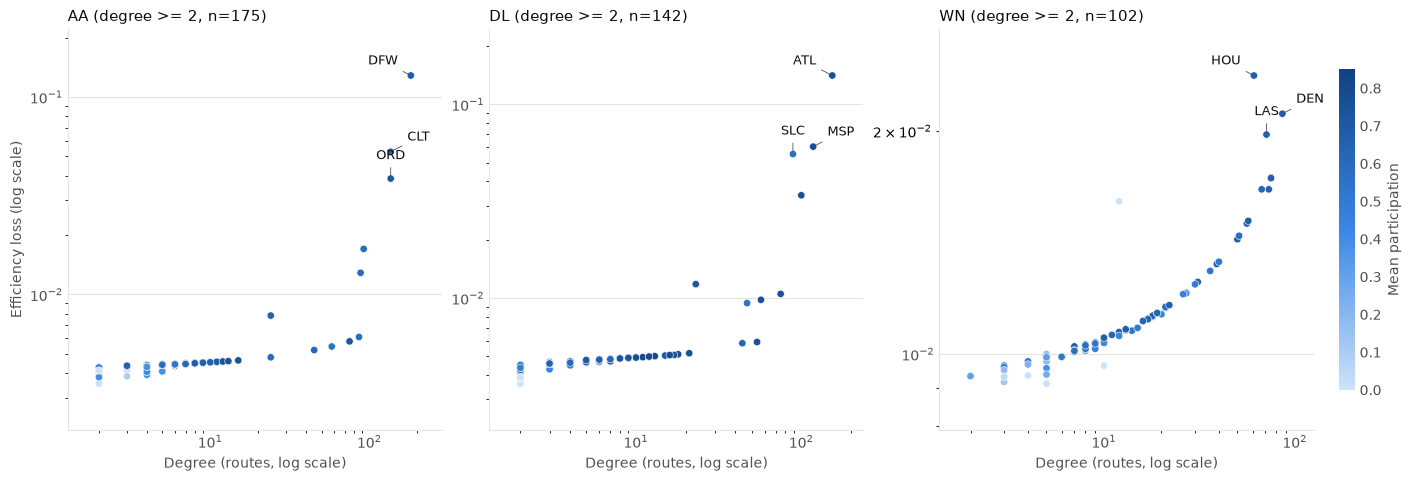

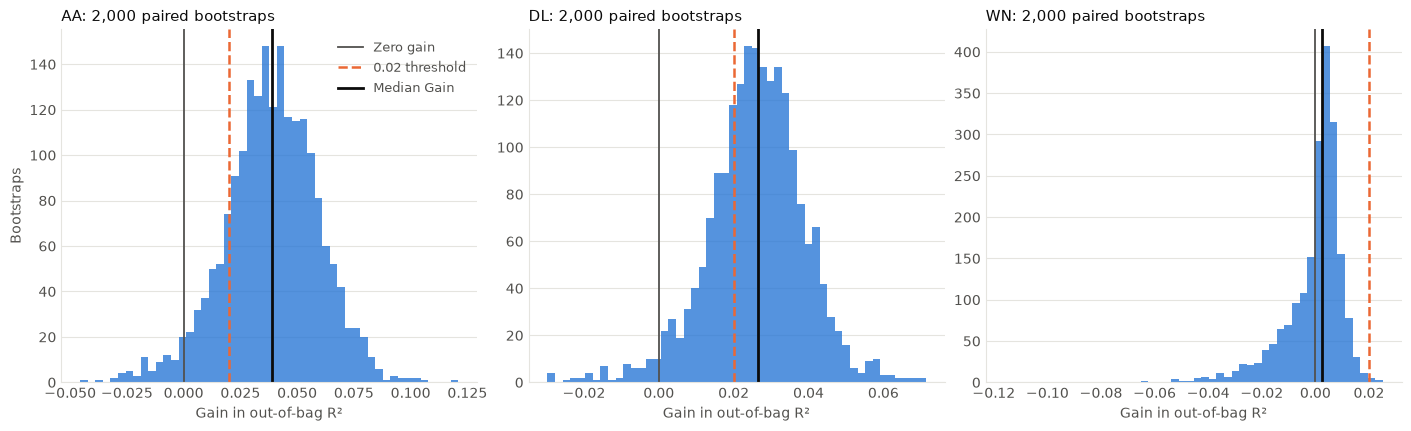

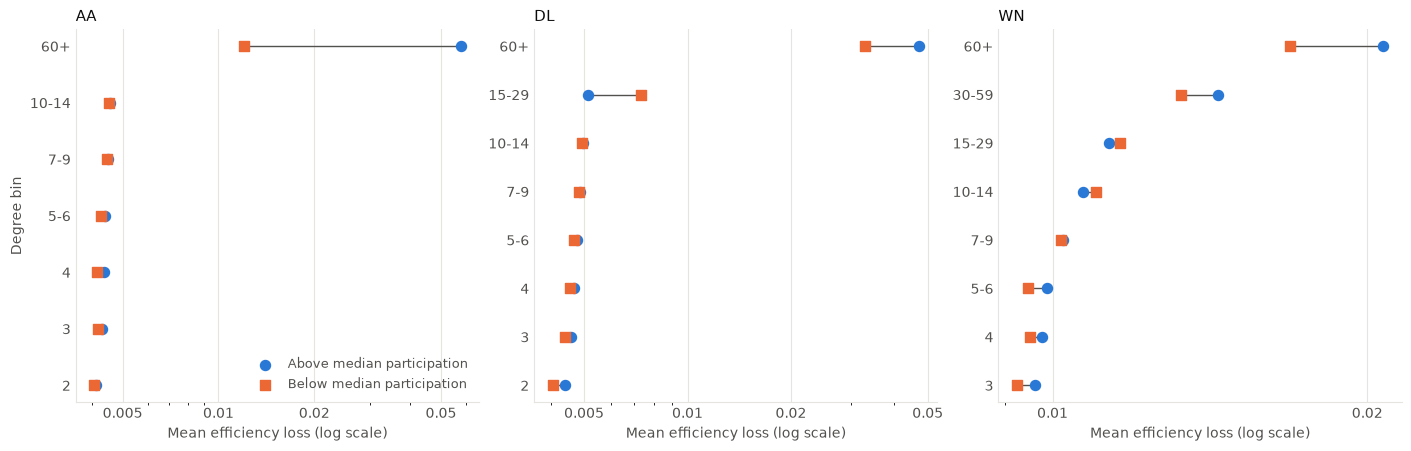

In [9]:
from matplotlib.colors import LinearSegmentedColormap

INK = "#0b0b0b"
MUTED = "#52514e"
GRID = "#e5e4df"
sequential = LinearSegmentedColormap.from_list("participation", ["#cde2fb", "#3987e5", "#104281"])


def style_axis(ax):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED, length=0)
    ax.yaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)


fig, axes = plt.subplots(1, 3, figsize=(14, 4.7), constrained_layout=True)
for ax, airline in zip(axes, AIRLINES):
    data = eligible_df[eligible_df["Airline"] == airline]
    points = ax.scatter(data["Degree"], data["Efficiency loss"], c=data["Participation mean"], cmap=sequential, vmin=0, vmax=0.85, s=28, edgecolor="white", linewidth=0.4)
    ax.set_xscale("log")
    ax.set_yscale("log")
    for offset, (_, row) in zip([(-20, 8), (20, 8), (0, 14)], data.nlargest(3, "Efficiency loss").iterrows()):
        ax.annotate(row["Code"], (row["Degree"], row["Efficiency loss"]), xytext=offset, textcoords="offset points", fontsize=9, color=INK, ha="center",
                    arrowprops={"arrowstyle": "-", "color": MUTED, "linewidth": 0.6})
    ax.set_xlabel("Degree (routes, log scale)", color=MUTED)
    ax.set_title(f"{airline} (degree >= 2, n={len(data)})", color=INK, fontsize=11, loc="left")
    ax.margins(x=0.1, y=0.15)
    style_axis(ax)
axes[0].set_ylabel("Efficiency loss (log scale)", color=MUTED)
colorbar = fig.colorbar(points, ax=axes, shrink=0.8, pad=0.012)
colorbar.set_label("Mean participation", color=MUTED)
colorbar.outline.set_visible(False)
colorbar.ax.tick_params(colors=MUTED, length=0)
fig.savefig(FIGURES / "07_loss_vs_degree_participation.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), constrained_layout=True)
for ax, airline in zip(axes, AIRLINES):
    gains = bootstrap_df[bootstrap_df["Airline"] == airline]["Gain"].dropna()
    performance = performance_df[performance_df["Airline"] == airline].iloc[0]
    ax.hist(gains, bins=50, color="#2a78d6", alpha=0.8)
    ax.axvline(0, color=MUTED, linewidth=1.3, label="Zero gain")
    ax.axvline(GAIN_THRESHOLD, color="#eb6834", linewidth=1.8, linestyle="--", label="0.02 threshold")
    ax.axvline(performance["Median Gain"], color=INK, linewidth=2, label="Median Gain")
    ax.set_xlabel("Gain in out-of-bag R²", color=MUTED)
    ax.set_title(f"{airline}: 2,000 paired bootstraps", color=INK, fontsize=11, loc="left")
    style_axis(ax)
axes[0].set_ylabel("Bootstraps", color=MUTED)
axes[0].legend(frameon=False, labelcolor=MUTED, fontsize=9)
fig.savefig(FIGURES / "07_h3_gain_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), constrained_layout=True)
for ax, airline in zip(axes, AIRLINES):
    data = bins_df[(bins_df["Airline"] == airline) & bins_df["Comparable"]].reset_index(drop=True)
    y = np.arange(len(data))
    ax.scatter(data["Mean loss above median"], y, s=52, color="#2a78d6", zorder=3, label="Above median participation")
    ax.scatter(data["Mean loss below median"], y, s=52, color="#eb6834", marker="s", zorder=3, label="Below median participation")
    ax.hlines(y, data["Mean loss below median"], data["Mean loss above median"], color=MUTED, linewidth=1)
    ax.set_yticks(y, data["Degree bin"].astype(str))
    ax.set_xscale("log")
    limits = ax.get_xlim()
    ax.set_xticks([tick for tick in (0.005, 0.01, 0.02, 0.05) if limits[0] <= tick <= limits[1]], labels=[f"{tick:g}" for tick in (0.005, 0.01, 0.02, 0.05) if limits[0] <= tick <= limits[1]])
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_xlim(limits)
    ax.set_xlabel("Mean efficiency loss (log scale)", color=MUTED)
    ax.set_title(airline, color=INK, fontsize=11, loc="left")
    style_axis(ax)
    ax.yaxis.grid(False)
    ax.xaxis.grid(True, color=GRID, linewidth=0.8)
axes[0].set_ylabel("Degree bin", color=MUTED)
axes[0].legend(frameon=False, labelcolor=MUTED, fontsize=9)
fig.savefig(FIGURES / "07_degree_matched_loss.png", dpi=300, bbox_inches="tight")
plt.show()

validation_df = pd.DataFrame(validation)
validation_df.to_csv(TABLES / "07_validation_checks.csv", index=False)
pd.DataFrame([{"Stage": key, "Seconds": value} for key, value in timings.items()]).to_csv(TABLES / "07_runtime.csv", index=False)
pd.DataFrame([{"Python": __import__("platform").python_version(), "NetworkX": nx.__version__, "NumPy": np.__version__, "pandas": pd.__version__, "SciPy": scipy.__version__,
               "Master seed": MASTER_SEED, "Bootstraps": BOOTSTRAPS, "Gain threshold (project-specific)": GAIN_THRESHOLD}]).to_csv(TABLES / "07_run_metadata.csv", index=False)
print(validation_df["Result"].value_counts().to_string())
print("These results describe association or predictive improvement, not causation. Report writing has not started.")

> Historical stage note: this describes the state when this section was first executed. Steps 1–7 are now complete; see the final report and validation record for current status.

### Step 7 status

All 76 validation checks passed, and the outputs were identical across two complete runs.

**H3 (approved rule):** Partly supported for AA, DL and WN. AA and DL meet the partial-correlation and degree-matched conditions. Their median Gain exceeds 0.02 R², but the Gain interval includes 0, so the Gain condition is not met. WN meets only the degree-matched condition.

These results describe association and predictive improvement in observed structure. They are not causal claims. The 0.02 R² threshold is a project-specific practical-effect threshold, and airports from one network are not independent observations.

Report writing has not started.